# R Programming — Assignment 4
## Image Recognition and Classification Using R, Keras and TensorFlow

**Name:** Tanishq Kulkarni  
**Roll No.:** 24102A2007  
**Branch / Division:** CMPN-A  
**Subject:** R Programming  
**Lab Problem:** 4 — R Project Implementation and Version Control Using GitHub

### Project Objective
To implement an end-to-end image recognition and classification project in **R** using a **Convolutional Neural Network (CNN)**. The project follows the prescribed image-classification workflow: load image data, inspect it, preprocess it, construct a neural-network model, train the model, evaluate its performance, generate predictions, visualize results, save outputs, and prepare the project for Git/GitHub version control.

### Dataset
This implementation uses the **Fashion-MNIST** dataset, a standard image-classification dataset containing:
- 60,000 training images
- 10,000 testing images
- 28 × 28 grayscale images
- 10 fashion categories

Using Fashion-MNIST makes the notebook fully reproducible because the dataset can be downloaded directly through Keras without manually collecting image files.


## 1. Install and Load Required Packages

The project uses the modern R interface to Keras. `keras3` provides the neural-network API and uses TensorFlow as the backend.

> Run the installation cell only if the packages are not already installed. The first TensorFlow setup may take some time.


In [ ]:
# Install required R packages if they are missing
required_packages <- c("keras3", "ggplot2")

for (pkg in required_packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) {
    install.packages(pkg)
  }
}

library(keras3)
library(ggplot2)

cat("Required R packages loaded successfully.\n")


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘RcppTOML’, ‘here’, ‘png’, ‘config’, ‘tfautograph’, ‘reticulate’, ‘tensorflow’, ‘tfruns’, ‘zeallot’, ‘dotty’




Required R packages loaded successfully.


## 2. Load the Fashion-MNIST Dataset

Fashion-MNIST contains labeled images belonging to ten classes. Keras automatically downloads and separates the training and testing data.


In [ ]:
set.seed(42)

fashion <- dataset_fashion_mnist()

x_train <- fashion$train$x
y_train <- fashion$train$y

x_test <- fashion$test$x
y_test <- fashion$test$y

cat("Training images:", dim(x_train), "\n")
cat("Training labels:", length(y_train), "\n")
cat("Testing images :", dim(x_test), "\n")
cat("Testing labels :", length(y_test), "\n")


Training images: 60000 28 28 
Training labels: 60000 
Testing images : 10000 28 28 
Testing labels : 10000 


## 3. Understand the Dataset


In [ ]:
class_names <- c(
  "T-shirt/top",
  "Trouser",
  "Pullover",
  "Dress",
  "Coat",
  "Sandal",
  "Shirt",
  "Sneaker",
  "Bag",
  "Ankle boot"
)

cat("Number of classes:", length(class_names), "\n")
cat("Image height:", dim(x_train)[2], "\n")
cat("Image width :", dim(x_train)[3], "\n")
cat("Pixel value range:", min(x_train), "to", max(x_train), "\n")

table(
  Class = factor(y_train, levels = 0:9, labels = class_names)
)


Number of classes: 10 
Image height: 28 
Image width : 28 
Pixel value range: 0 to 255 


Class
T-shirt/top     Trouser    Pullover       Dress        Coat      Sandal 
       6000        6000        6000        6000        6000        6000 
      Shirt     Sneaker         Bag  Ankle boot 
       6000        6000        6000        6000 

## 4. Visualize Sample Images

The following code displays example images with their true class labels. This helps verify that the image data and labels were loaded correctly.


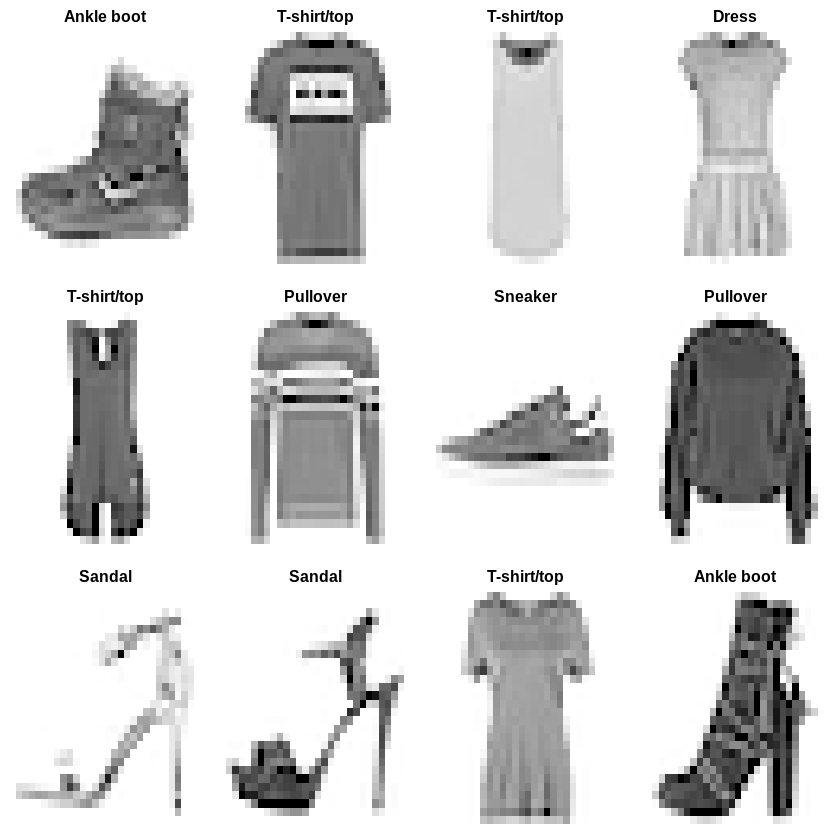

In [ ]:
par(mfrow = c(3, 4), mar = c(1, 1, 2, 1))

for (i in 1:12) {
  img <- x_train[i, , ]

  image(
    t(apply(img, 2, rev)),
    col = gray.colors(256, start = 1, end = 0),
    axes = FALSE,
    main = class_names[y_train[i] + 1]
  )
}

par(mfrow = c(1, 1))


## 5. Image Pre-processing

Neural networks learn more effectively when pixel values are scaled to a small numerical range.

### Operations performed
1. Convert pixel values from `0–255` to `0–1`.
2. Reshape each image from `28 × 28` to `28 × 28 × 1` so that it can be passed to a convolutional neural network.


In [ ]:
# Normalize pixel values
x_train <- x_train / 255
x_test <- x_test / 255

# Add the single grayscale channel dimension
x_train <- array_reshape(
  x_train,
  c(dim(x_train)[1], 28, 28, 1)
)

x_test <- array_reshape(
  x_test,
  c(dim(x_test)[1], 28, 28, 1)
)

cat("Training data shape after preprocessing:", dim(x_train), "\n")
cat("Testing data shape after preprocessing :", dim(x_test), "\n")
cat("Normalized pixel range:", min(x_train), "to", max(x_train), "\n")


Training data shape after preprocessing: 60000 28 28 1 
Testing data shape after preprocessing : 10000 28 28 1 
Normalized pixel range: 0 to 1 


## 6. Build the CNN Model

A **Convolutional Neural Network (CNN)** is appropriate for image recognition because convolutional layers learn local visual patterns such as edges, shapes, textures, and object parts.

### Architecture
- Conv2D — 32 filters
- Conv2D — 64 filters
- Max Pooling
- Dropout
- Flatten
- Dense — 128 neurons
- Dropout
- Output Dense — 10 neurons with Softmax


In [ ]:
model <- keras_model_sequential(input_shape = c(28, 28, 1)) |>
  layer_conv_2d(
    filters = 32,
    kernel_size = c(3, 3),
    activation = "relu",
    padding = "same"
  ) |>
  layer_conv_2d(
    filters = 64,
    kernel_size = c(3, 3),
    activation = "relu",
    padding = "same"
  ) |>
  layer_max_pooling_2d(pool_size = c(2, 2)) |>
  layer_dropout(rate = 0.25) |>
  layer_flatten() |>
  layer_dense(units = 128, activation = "relu") |>
  layer_dropout(rate = 0.50) |>
  layer_dense(units = 10, activation = "softmax")

summary(model)


Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                   │ (None, 28, 28, 32)       │           320 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)                 │ (None, 28, 28, 64)       │        18,496 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)      │ (None, 14, 14, 64)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout (Dropout)                 │ (None, 14, 14, 64)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ flatten (Flatten)                 │ (None, 12544)            │             0 │
├───────

## 7. Compile the Model

- **Optimizer:** Adam
- **Loss:** Sparse Categorical Cross-Entropy
- **Metric:** Accuracy

Sparse categorical cross-entropy is used because the target labels are integer class IDs from 0 to 9.


In [ ]:
model |> compile(
  optimizer = "adam",
  loss = "sparse_categorical_crossentropy",
  metrics = c("accuracy")
)

cat("Model compiled successfully.\n")


Model compiled successfully.


## 8. Train the Model

The training data is used to learn model parameters.  
`validation_split = 0.2` reserves 20% of the training samples for validation during training.


In [ ]:
history <- model |> fit(
  x = x_train,
  y = y_train,
  epochs = 8,
  batch_size = 128,
  validation_split = 0.20,
  verbose = 2
)


## 9. Plot Training and Validation Performance


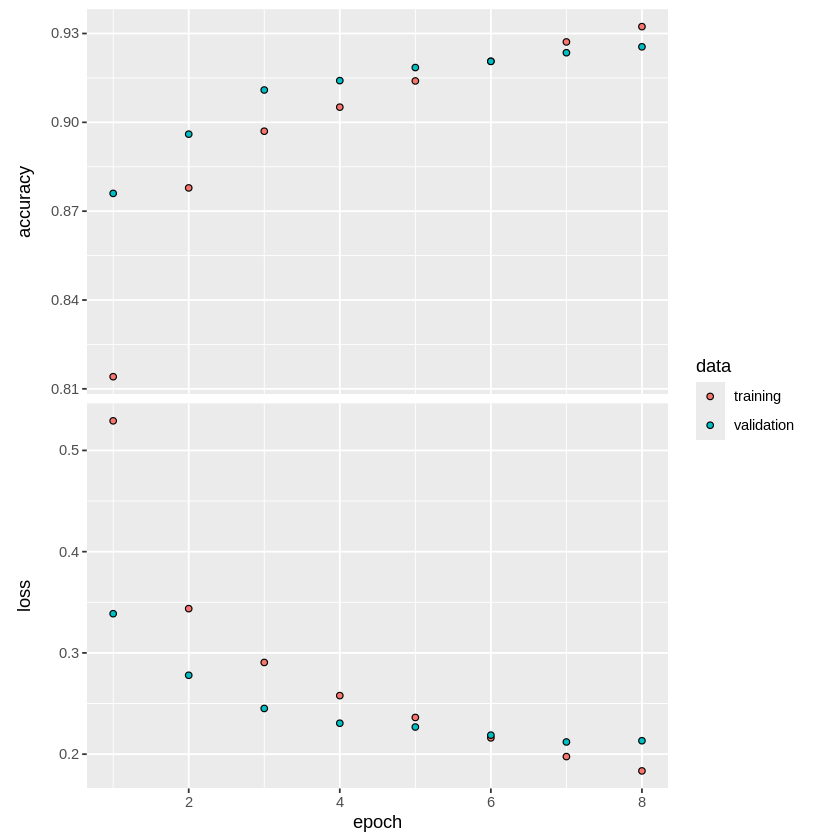

In [ ]:
plot(history)


The graph should show how training/validation loss and accuracy change across epochs. A useful model should show increasing accuracy and decreasing loss while avoiding a large gap between training and validation results.


## 10. Evaluate the Model on Unseen Test Data

The test set is not used to update model parameters. Therefore, test performance gives a better estimate of how well the classifier generalizes to unseen images.


In [ ]:
test_results <- model |> evaluate(
  x_test,
  y_test,
  verbose = 0
)

cat(
  sprintf(
    "Test Loss: %.4f\nTest Accuracy: %.2f%%\n",
    test_results["loss"],
    test_results["accuracy"] * 100
  )
)


ERROR: Error in test_results["accuracy"] * 100: non-numeric argument to binary operator


## 11. Generate Predictions


In [ ]:
probabilities <- model |> predict(x_test, verbose = 0)

# Convert class probabilities into predicted class IDs (0-9)
predicted_class <- max.col(probabilities) - 1

prediction_results <- data.frame(
  Actual_ID = y_test,
  Predicted_ID = predicted_class,
  Actual_Class = class_names[y_test + 1],
  Predicted_Class = class_names[predicted_class + 1],
  Correct = predicted_class == y_test
)

head(prediction_results, 20)


## 12. Confusion Matrix

A confusion matrix shows the number of correct and incorrect predictions for every class.


In [ ]:
confusion_matrix <- table(
  Actual = factor(
    y_test,
    levels = 0:9,
    labels = class_names
  ),
  Predicted = factor(
    predicted_class,
    levels = 0:9,
    labels = class_names
  )
)

confusion_matrix


## 13. Calculate Classification Accuracy Manually


In [ ]:
manual_accuracy <- mean(predicted_class == y_test)

cat(
  sprintf(
    "Correct predictions: %d / %d\n",
    sum(predicted_class == y_test),
    length(y_test)
  )
)

cat(
  sprintf(
    "Manual Test Accuracy: %.2f%%\n",
    manual_accuracy * 100
  )
)


## 14. Class-wise Accuracy

This analysis identifies which categories are easier or harder for the model to recognize.


In [ ]:
class_accuracy <- data.frame(
  Class_ID = 0:9,
  Class = class_names,
  Accuracy = sapply(0:9, function(k) {
    idx <- which(y_test == k)
    mean(predicted_class[idx] == y_test[idx])
  })
)

class_accuracy$Accuracy_Percent <- round(
  class_accuracy$Accuracy * 100,
  2
)

class_accuracy


In [ ]:
ggplot(
  class_accuracy,
  aes(
    x = reorder(Class, Accuracy_Percent),
    y = Accuracy_Percent
  )
) +
  geom_col() +
  coord_flip() +
  labs(
    title = "Class-wise Fashion-MNIST Classification Accuracy",
    x = "Fashion Category",
    y = "Accuracy (%)"
  ) +
  theme_minimal()


## 15. Visualize Model Predictions

Green/red coloring is intentionally avoided here so the notebook remains readable in different themes. Each image title shows the predicted and actual category.


In [ ]:
set.seed(42)
sample_ids <- sample(seq_len(dim(x_test)[1]), 12)

par(mfrow = c(3, 4), mar = c(1, 1, 3, 1))

for (id in sample_ids) {
  img <- x_test[id, , , 1]
  actual <- class_names[y_test[id] + 1]
  predicted <- class_names[predicted_class[id] + 1]

  image(
    t(apply(img, 2, rev)),
    col = gray.colors(256, start = 1, end = 0),
    axes = FALSE,
    main = paste0(
      "Pred: ", predicted,
      "\nActual: ", actual
    )
  )
}

par(mfrow = c(1, 1))


## 16. Inspect Misclassified Images

Misclassified samples are useful because they show where the model is confused.


In [ ]:
wrong_ids <- which(predicted_class != y_test)

cat("Number of misclassified test images:", length(wrong_ids), "\n")

if (length(wrong_ids) > 0) {
  show_ids <- head(wrong_ids, 12)

  par(mfrow = c(3, 4), mar = c(1, 1, 3, 1))

  for (id in show_ids) {
    img <- x_test[id, , , 1]

    image(
      t(apply(img, 2, rev)),
      col = gray.colors(256, start = 1, end = 0),
      axes = FALSE,
      main = paste0(
        "Pred: ", class_names[predicted_class[id] + 1],
        "\nActual: ", class_names[y_test[id] + 1]
      )
    )
  }

  par(mfrow = c(1, 1))
}


## 17. Save Project Outputs

The assignment requires generated results to be organized systematically. The following cell creates an `outputs/` directory and saves:
- prediction results
- confusion matrix
- class-wise accuracy
- trained model


In [ ]:
if (!dir.exists("outputs")) {
  dir.create("outputs")
}

write.csv(
  prediction_results,
  "outputs/test_predictions.csv",
  row.names = FALSE
)

write.csv(
  as.data.frame.matrix(confusion_matrix),
  "outputs/confusion_matrix.csv",
  row.names = TRUE
)

write.csv(
  class_accuracy,
  "outputs/class_accuracy.csv",
  row.names = FALSE
)

save_model(
  model,
  "outputs/fashion_mnist_cnn.keras"
)

cat("All output files saved successfully inside the outputs/ directory.\n")


## 18. Final Validation

This section verifies the essential project conditions programmatically.


In [ ]:
checks <- c(
  "Training samples available" = dim(x_train)[1] > 0,
  "Testing samples available" = dim(x_test)[1] > 0,
  "Ten target classes" = length(unique(y_train)) == 10,
  "Normalized image values" = min(x_train) >= 0 && max(x_train) <= 1,
  "Prediction count matches test data" = length(predicted_class) == length(y_test),
  "Accuracy is valid" = manual_accuracy >= 0 && manual_accuracy <= 1
)

print(checks)

if (all(checks)) {
  cat("\nFINAL VALIDATION PASSED: Project executed correctly.\n")
} else {
  cat("\nOne or more validation checks failed. Review the corresponding section.\n")
}


# Project Conclusion

The image recognition and classification project was successfully implemented in R using Keras and TensorFlow. Fashion-MNIST images were imported, explored, normalized, reshaped, and passed to a convolutional neural network. The CNN learned visual features using convolutional layers and produced probabilities for ten fashion categories using a softmax output layer.

The trained model was evaluated on an independent test dataset. Its performance was analyzed using test accuracy, a confusion matrix, class-wise accuracy, prediction samples, and misclassified examples. The implementation therefore demonstrates a complete data-science workflow involving data acquisition, preprocessing, modeling, validation, interpretation, result generation, and reproducibility.

The project can be further improved through additional epochs, hyperparameter tuning, data augmentation, deeper CNN architectures, transfer learning, or deployment through a web interface.


# 19. Git and GitHub Version Control

The assignment requires **meaningful commits at different stages**, not a single final upload.

Run the following commands from the folder containing this notebook.

```bash
git init

git add R_Programming_Assignment_4_Image_Classification.ipynb
git commit -m "Initialize R image classification project"

git add .
git commit -m "Add Fashion-MNIST preprocessing workflow"

git add .
git commit -m "Implement CNN image classification model"

git add .
git commit -m "Add evaluation confusion matrix and predictions"

git add README.md
git commit -m "Add project documentation"

git branch -M main
git remote add origin https://github.com/YOUR_USERNAME/r-image-classification.git
git push -u origin main
```

### Suggested Repository Structure

```text
r-image-classification/
│
├── R_Programming_Assignment_4_Image_Classification.ipynb
├── README.md
├── .gitignore
│
└── outputs/
    ├── test_predictions.csv
    ├── confusion_matrix.csv
    ├── class_accuracy.csv
    └── fashion_mnist_cnn.keras
```

> The Fashion-MNIST dataset itself does not need to be committed because Keras downloads it automatically. Mention this clearly in the README.


# 20. Generate README.md Automatically

Execute the next R cell once the notebook has been run successfully. It creates a `README.md` containing all documentation items required by the assignment.


In [ ]:
readme <- c(
"# Fashion-MNIST Image Recognition and Classification in R",
"",
"## Objective",
"To implement an end-to-end image recognition and classification project using R, Keras, TensorFlow, and a Convolutional Neural Network (CNN).",
"",
"## Problem Description",
"The project trains a CNN to recognize 28x28 grayscale images of fashion products and classify them into one of ten categories.",
"",
"## Dataset",
"Fashion-MNIST is used through the Keras dataset API. It contains 60,000 training images and 10,000 testing images distributed across ten fashion categories. The dataset is downloaded automatically when the notebook is executed.",
"",
"## R Packages / Libraries Used",
"- keras3",
"- TensorFlow backend",
"- ggplot2",
"",
"## Major Operations Performed",
"1. Load Fashion-MNIST dataset",
"2. Inspect and visualize images",
"3. Normalize pixel values",
"4. Reshape images for CNN input",
"5. Build and compile a CNN",
"6. Train with validation split",
"7. Evaluate on unseen test data",
"8. Generate predictions",
"9. Create confusion matrix",
"10. Calculate class-wise accuracy",
"11. Inspect misclassified images",
"12. Save model and generated results",
"",
"## How to Execute",
"1. Install R and RStudio or use an R-enabled notebook environment.",
"2. Open `R_Programming_Assignment_4_Image_Classification.ipynb`.",
"3. Install `keras3` and `ggplot2` if required.",
"4. Configure the TensorFlow backend if it is not already available.",
"5. Run all notebook cells in sequence.",
"6. Generated files will be stored inside the `outputs/` directory.",
"",
"## Important Results",
"The notebook prints test loss and test accuracy after training. It also generates a confusion matrix, class-wise accuracy table, prediction examples, and misclassified-image analysis. Exact numerical results can vary slightly across executions because neural-network training is stochastic.",
"",
"## Output Files",
"- `outputs/test_predictions.csv`",
"- `outputs/confusion_matrix.csv`",
"- `outputs/class_accuracy.csv`",
"- `outputs/fashion_mnist_cnn.keras`",
"",
"## Screenshots",
"Add screenshots of:",
"- sample Fashion-MNIST images",
"- CNN model summary",
"- training/validation graph",
"- final test accuracy",
"- confusion matrix/output",
"- prediction visualization",
"- successful GitHub repository page",
"",
"## Reference",
"Prescribed Assignment 4 tutorial: Image Recognition and Classification using R/Keras.",
"",
"## Conclusion",
"The project demonstrates a complete R-based image classification workflow from data loading and preprocessing to deep-learning model construction, testing, evaluation, documentation, and version control."
)

writeLines(readme, "README.md")

cat("README.md created successfully.\\n")
